CELL 1- Install Libraries

In [ ]:
!pip install datasets pandas numpy matplotlib

Cell 2- Import Libraries


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


Cell 3- Download The Public Dataset

In [ ]:
from datasets import load_dataset

weather = load_dataset(
    "AkshayKarthick/india-weather-air-quality",
    "weather",
    split="train"
).to_pandas()

air = load_dataset(
    "AkshayKarthick/india-weather-air-quality",
    "air_quality",
    split="train"
).to_pandas()

cities = load_dataset(
    "AkshayKarthick/india-weather-air-quality",
    "cities",
    split="train"
).to_pandas()

print("All datasets downloaded!")

README.md:   0%|          | 0.00/8.04k [00:00<?, ?B/s]

weather_daily.csv:   0%|          | 0.00/9.11M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/125750 [00:00<?, ? examples/s]

air_quality_daily.csv:   0%|          | 0.00/8.77M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/78400 [00:00<?, ? examples/s]

cities.csv:   0%|          | 0.00/2.42k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/50 [00:00<?, ? examples/s]

All datasets downloaded!


Cell 4- Combining All The Datasets

In [ ]:

weather["date"] = pd.to_datetime(weather["date"])
air["date"] = pd.to_datetime(air["date"])

df = pd.merge(
    weather,
    air,
    on=["city", "date"],
    how="inner",
    validate="one_to_one"
)

df = pd.merge(
    df,
    cities,
    on="city",
    how="left",
    validate="many_to_one"
)

print(df.head())
print("Final dataset size:", df.shape)

        date      city  temperature_2m_max  temperature_2m_min  \
0 2022-08-05  Agartala                33.3                25.7   
1 2022-08-06  Agartala                32.4                25.4   
2 2022-08-07  Agartala                33.8                25.7   
3 2022-08-08  Agartala                33.1                25.5   
4 2022-08-09  Agartala                32.9                25.5   

   temperature_2m_mean  apparent_temperature_max  precipitation_sum  \
0                 29.0                      41.7               12.1   
1                 28.1                      40.8                8.7   
2                 29.5                      42.2                0.3   
3                 28.4                      40.3               12.8   
4                 28.3                      38.4                2.4   

   precipitation_hours  relative_humidity_2m_mean  wind_speed_10m_max  ...  \
0                  7.0                         83                10.5  ...   
1                 17

Cell 5- Data Quality Report

In [ ]:

print("Missing Values:")
print(df.isnull().sum())
print("Duplicate Rows:", df.duplicated().sum())
print(df.dtypes)
print("Start Date:", df["date"].min())
print("End Date:", df["date"].max())
print("Total Cities:", df["city"].nunique())

Missing Values:
date                           0
city                           0
temperature_2m_max             0
temperature_2m_min             0
temperature_2m_mean            0
apparent_temperature_max       0
precipitation_sum              0
precipitation_hours            0
relative_humidity_2m_mean      0
wind_speed_10m_max             0
wind_direction_10m_dominant    0
shortwave_radiation_sum        0
et0_fao_evapotranspiration     0
weather_code                   0
pm2_5_mean                     0
pm2_5_max                      0
pm10_mean                      0
pm10_max                       0
no2_mean                       0
so2_mean                       0
o3_8h_max                      0
co_8h_max                      0
dust_mean                      0
aod_mean                       0
us_aqi_max                     0
hours_available                0
india_aqi                      0
india_aqi_category             0
dominant_pollutant             0
india_aqi_pm               

Cell 6- Cleaning The Data

In [ ]:

df = df.drop_duplicates()
pollutants = [
    "pm2_5_mean",
    "pm10_mean",
    "no2_mean",
    "o3_8h_max"
]

for col in pollutants:
    df.loc[df[col] < 0, col] = np.nan
df = df.dropna(
    subset=[
        "city",
        "date",
        "pm2_5_mean",
        "pm10_mean"
    ]
)

print("Data cleaning completed!")
print(df.shape)

Data cleaning completed!
(78400, 36)


Cell 7- Standarlising the data and Checking The Extreme Levels

In [ ]:

df["city"] = df["city"].str.strip().str.title()
for col in pollutants:

    lower = df[col].quantile(0.01)
    upper = df[col].quantile(0.99)

    print(col)
    print("1st Percentile:", lower)
    print("99th Percentile:", upper)
    df[col + "_extreme"] = (
        (df[col] < lower) |
        (df[col] > upper)
    )

print("Extreme value checking completed!")

pm2_5_mean
1st Percentile: 3.12
99th Percentile: 142.11009999999996
pm10_mean
1st Percentile: 4.68
99th Percentile: 273.0502999999999
no2_mean
1st Percentile: 0.36
99th Percentile: 68.91
o3_8h_max
1st Percentile: 42.38
99th Percentile: 219.0
Extreme value checking completed!


Cell 8-NUM PY Analysis

In [ ]:
pm = df["pm2_5_mean"].dropna().to_numpy()

print("Mean:", np.mean(pm))

print("Median:", np.median(pm))

print("Standard Deviation:", np.std(pm))

print("25th Percentile:", np.percentile(pm, 25))

print("75th Percentile:", np.percentile(pm, 75))

print("90th Quantile:", np.quantile(pm, 0.90))

print("Maximum:", np.max(pm))

print("Minimum:", np.min(pm))
print("Values above 60:", np.count_nonzero(pm > 60))
high_pollution = np.where(pm > 60, "High", "Normal")

print("High pollution days:", np.count_nonzero(high_pollution == "High"))

Mean: 35.66053596938776
Median: 28.25
Standard Deviation: 28.14245277290133
25th Percentile: 16.8
75th Percentile: 45.58
90th Quantile: 70.51100000000007
Maximum: 279.78
Minimum: 0.48
Values above 60: 11289
High pollution days: 11289


Cell 9- Pollutant Summary

In [ ]:
pollutant_summary = df[pollutants].agg(
    ["mean", "median", "min", "max", "std"]
)

print(pollutant_summary)

        pm2_5_mean    pm10_mean    no2_mean   o3_8h_max
mean     35.660536    56.286871   15.604821  123.433056
median   28.250000    41.400000   11.780000  125.750000
min       0.480000     0.620000    0.000000   17.880000
max     279.780000  1788.140000  156.980000  715.880000
std      28.142632    62.434209   13.425992   40.421684


Cell 10- City-wise Analysis

In [ ]:
city_hotspots = df.groupby("city").agg(
    average_pm25=("pm2_5_mean", "mean"),
    average_pm10=("pm10_mean", "mean"),
    average_no2=("no2_mean", "mean"),
    average_aqi=("india_aqi_pm", "mean"),
    total_days=("date", "count")
)

city_hotspots = city_hotspots.sort_values(
    by="average_pm25",
    ascending=False
)

print("Top 10 cities by average PM2.5:")
print(city_hotspots.head(10))

Top 10 cities by average PM2.5:
           average_pm25  average_pm10  average_no2  average_aqi  total_days
city                                                                       
Delhi         74.623151    162.821767    40.304962   183.021684        1568
Agra          70.110874    195.344362    26.720096   191.937500        1568
Amritsar      65.789407     96.025938    22.923846   132.677934        1568
Ludhiana      64.992557    104.145242    22.397130   136.139031        1568
Patna         61.694420     83.062194    18.276626   123.141582        1568
Lucknow       58.216779     94.383948    18.482219   123.362883        1568
Kolkata       58.082889     74.885727    22.932634   117.373724        1568
Prayagraj     57.492602     84.216167    18.720077   117.255102        1568
Kanpur        56.781990    117.125593    19.021103   137.795918        1568
Varanasi      56.656626     81.063176    17.535185   113.978316        1568


Cell 11-Monthly Pollution Analysis

In [ ]:
df["month"] = df["date"].dt.month

monthly_data = df.groupby("month").agg(
    average_pm25=("pm2_5_mean", "mean"),
    average_pm10=("pm10_mean", "mean"),
    average_temperature=("temperature_2m_mean", "mean")
)

print(monthly_data)

       average_pm25  average_pm10  average_temperature
month                                                 
1         61.541018     77.468047            17.554048
2         44.554568     60.073839            20.662584
3         36.175531     67.188627            24.065048
4         29.574170     64.405707            27.596183
5         29.387142     66.851755            28.810532
6         26.943958     58.904038            28.798533
7         20.560516     35.393631            26.978613
8         20.974331     34.926121            26.473086
9         22.872472     33.742611            26.179853
10        34.733436     51.747071            24.654142
11        51.276321     67.574973            21.718504
12        53.866381     66.995898            18.745210


Cell 12- Seasonal Analysis

In [ ]:
def get_season(month):

    if month in [12, 1, 2]:
        return "Winter"

    elif month in [3, 4, 5]:
        return "Summer"

    elif month in [6, 7, 8, 9]:
        return "Monsoon"

    else:
        return "Post-Monsoon"


df["season"] = df["date"].dt.month.apply(get_season)

season_analysis = df.groupby("season").agg(
    pm25=("pm2_5_mean", "mean"),
    pm10=("pm10_mean", "mean"),
    temperature=("temperature_2m_mean", "mean"),
    humidity=("relative_humidity_2m_mean", "mean"),
    wind=("wind_speed_10m_max", "mean")
)

print(season_analysis)

                   pm25       pm10  temperature   humidity       wind
season                                                               
Monsoon       22.717016  39.986295    27.019424  77.669394  15.808349
Post-Monsoon  42.554732  59.230331    23.266204  69.338299  11.817796
Summer        31.735521  66.167642    26.815527  55.041087  15.976440
Winter        53.587766  68.426241    18.936233  65.212964  12.554000


Cell 13- Weather and Pollution Connection

In [ ]:
weather_columns = [
    "temperature_2m_mean",
    "relative_humidity_2m_mean",
    "wind_speed_10m_max",
    "precipitation_sum",
    "pm2_5_mean",
    "pm10_mean",
    "no2_mean",
    "o3_8h_max"
]

correlation = df[weather_columns].corr()

print(correlation)

                           temperature_2m_mean  relative_humidity_2m_mean  \
temperature_2m_mean                   1.000000                  -0.074727   
relative_humidity_2m_mean            -0.074727                   1.000000   
wind_speed_10m_max                    0.401860                  -0.013014   
precipitation_sum                     0.035691                   0.405937   
pm2_5_mean                           -0.168188                  -0.092657   
pm10_mean                             0.039385                  -0.223484   
no2_mean                             -0.107078                  -0.114653   
o3_8h_max                            -0.007644                  -0.424837   

                           wind_speed_10m_max  precipitation_sum  pm2_5_mean  \
temperature_2m_mean                  0.401860           0.035691   -0.168188   
relative_humidity_2m_mean           -0.013014           0.405937   -0.092657   
wind_speed_10m_max                   1.000000           0.156927  

Cell 14- Identity Pollution Leve;l Increase

In [ ]:

city_average = df.groupby("city")["pm2_5_mean"].transform("mean")
df = df.sort_values(["city", "date"])

df["rolling_pm25"] = (
    df.groupby("city")["pm2_5_mean"]
    .transform(lambda x: x.rolling(7, min_periods=3).mean())
)
city_std = df.groupby("city")["pm2_5_mean"].transform("std")

df["pollution_spike"] = (
    df["pm2_5_mean"] > city_average + 2 * city_std
)

print("Pollution spike records:")
print(df[df["pollution_spike"]][
    ["city", "date", "pm2_5_mean"]
].head(20))

Pollution spike records:
         city       date  pm2_5_mean
145  Agartala 2022-12-28       98.72
146  Agartala 2022-12-29      124.49
147  Agartala 2022-12-30      125.66
148  Agartala 2022-12-31      125.54
160  Agartala 2023-01-12      100.51
161  Agartala 2023-01-13      121.90
162  Agartala 2023-01-14      101.71
163  Agartala 2023-01-15       99.08
166  Agartala 2023-01-18      102.62
167  Agartala 2023-01-19      103.50
168  Agartala 2023-01-20      118.05
169  Agartala 2023-01-21      123.92
170  Agartala 2023-01-22      111.20
171  Agartala 2023-01-23      124.17
172  Agartala 2023-01-24      104.75
173  Agartala 2023-01-25      119.65
174  Agartala 2023-01-26      147.83
175  Agartala 2023-01-27      147.17
179  Agartala 2023-01-31      101.49
184  Agartala 2023-02-05      103.69


Cell 15- Pandas Pivot Table

In [ ]:
pivot = pd.pivot_table(
    df,
    values="pm2_5_mean",
    index="city",
    columns="season",
    aggfunc="mean"
)

print(pivot.head(10))

season         Monsoon  Post-Monsoon     Summer      Winter
city                                                       
Agartala     17.853633     44.697687  44.680598   73.105180
Agra         41.606844     84.550986  72.033370   99.423407
Ahmedabad    20.055541     43.810544  21.605326   40.270637
Amritsar     48.625101     78.399286  39.856304  107.868698
Bengaluru     9.623560     25.148265  26.789049   28.719501
Bhopal       19.006697     38.730850  21.801196   38.843823
Bhubaneswar  23.711890     50.743844  29.830543   72.162216
Chandigarh   40.164936     43.020918  28.635625   58.391579
Chennai      19.492972     23.706973  19.818777   30.482105
Coimbatore    7.797266     21.465884  22.165978   26.644931


Cell 16- Find High Pollution Records

In [ ]:
high_pollution_days = df.query("pm2_5_mean > 60")

print(high_pollution_days[
    ["city", "date", "pm2_5_mean"]
].head(20))

         city       date  pm2_5_mean
83   Agartala 2022-10-27       70.67
84   Agartala 2022-10-28       63.79
92   Agartala 2022-11-05       65.62
93   Agartala 2022-11-06       69.14
94   Agartala 2022-11-07       74.60
100  Agartala 2022-11-13       69.84
101  Agartala 2022-11-14       63.00
117  Agartala 2022-11-30       74.47
124  Agartala 2022-12-07       61.42
128  Agartala 2022-12-11       65.48
129  Agartala 2022-12-12       71.77
130  Agartala 2022-12-13       61.62
133  Agartala 2022-12-16       65.84
134  Agartala 2022-12-17       76.12
136  Agartala 2022-12-19       67.12
137  Agartala 2022-12-20       91.90
138  Agartala 2022-12-21       92.07
139  Agartala 2022-12-22       97.16
140  Agartala 2022-12-23       92.17
141  Agartala 2022-12-24       81.34


Cell 17- Create five Visualisations

Graph 1 -

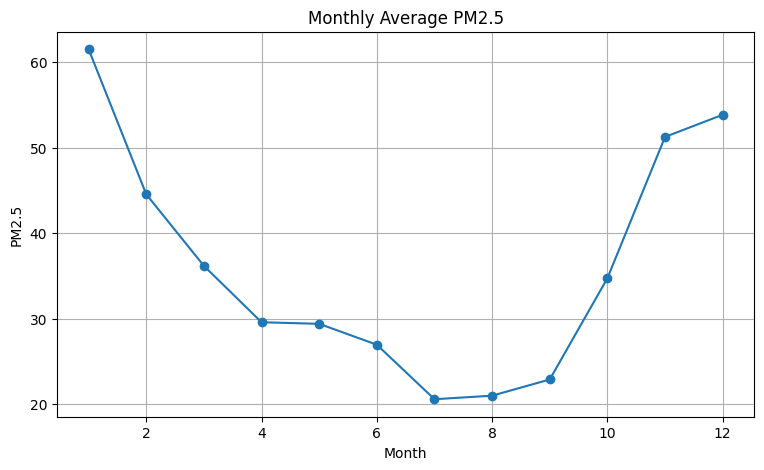

In [ ]:
monthly_data["average_pm25"].plot(
    kind="line",
    marker="o",
    figsize=(9, 5)
)

plt.title("Monthly Average PM2.5")
plt.xlabel("Month")
plt.ylabel("PM2.5")
plt.grid()
plt.show()

Graph 2- Seasonal Pollution

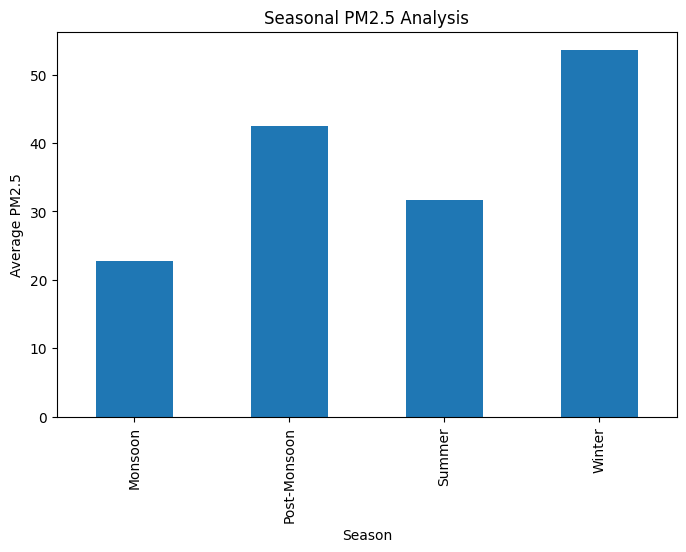

In [ ]:
season_analysis["pm25"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Seasonal PM2.5 Analysis")
plt.xlabel("Season")
plt.ylabel("Average PM2.5")
plt.show()

Graph 3- Weather coorelation heatmap

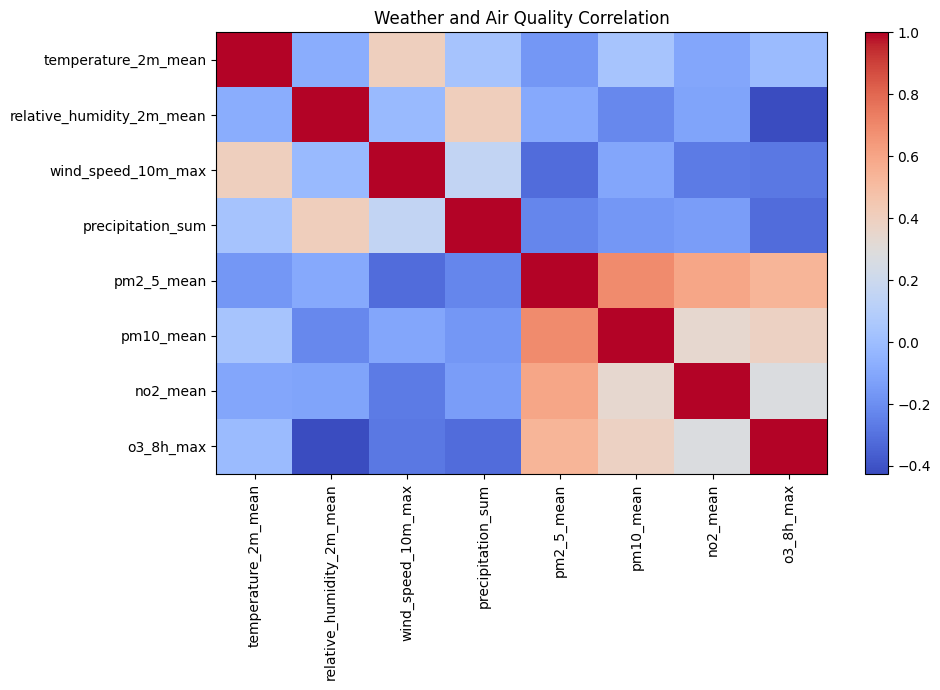

In [ ]:
plt.figure(figsize=(10, 7))

plt.imshow(correlation, cmap="coolwarm", aspect="auto")

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Weather and Air Quality Correlation")

plt.tight_layout()
plt.show()

Graph 4- Top 10 polluted cities

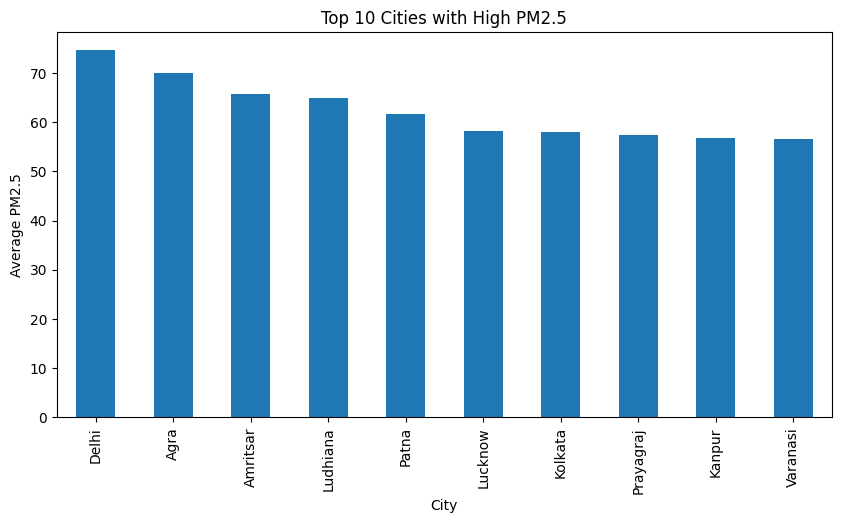

In [ ]:
city_hotspots["average_pm25"].head(10).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Top 10 Cities with High PM2.5")
plt.xlabel("City")
plt.ylabel("Average PM2.5")
plt.show()

Graph 5- Temperature vs pm2.5

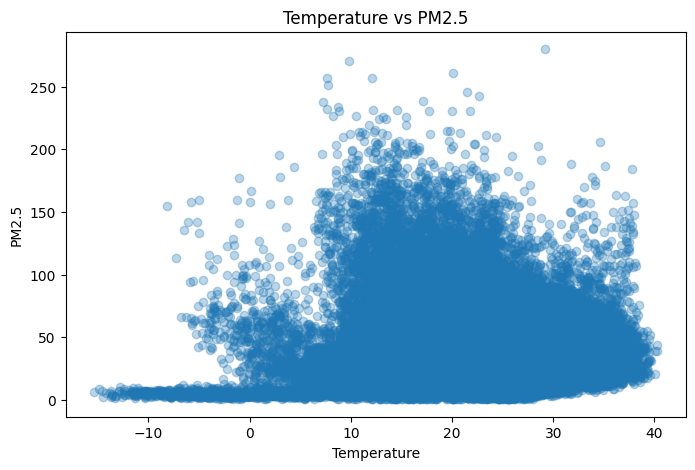

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["temperature_2m_mean"],
    df["pm2_5_mean"],
    alpha=0.3
)

plt.title("Temperature vs PM2.5")
plt.xlabel("Temperature")
plt.ylabel("PM2.5")
plt.show()

Cell 18

In [ ]:
print("========== PROJECT FINDINGS ==========")

print("1. Total cities:", df["city"].nunique())

print("2. Total records:", len(df))

print("3. Average PM2.5:",
      round(df["pm2_5_mean"].mean(), 2))

print("4. Average PM10:",
      round(df["pm10_mean"].mean(), 2))

print("5. Average temperature:",
      round(df["temperature_2m_mean"].mean(), 2))

print("6. Average humidity:",
      round(df["relative_humidity_2m_mean"].mean(), 2))

print("7. City with highest average PM2.5:",
      city_hotspots["average_pm25"].idxmax())

print("8. Season with highest average PM2.5:",
      season_analysis["pm25"].idxmax())

print("========== END OF FINDINGS ==========")

========== PROJECT FINDINGS ==========
1. Total cities: 50
2. Total records: 78400
3. Average PM2.5: 35.66
4. Average PM10: 56.29
5. Average temperature: 24.41
6. Average humidity: 67.93
7. City with highest average PM2.5: Delhi
8. Season with highest average PM2.5: Winter
========== END OF FINDINGS ==========


Cell 19

In [ ]:

df.to_csv("clean_air_quality.csv", index=False)
city_hotspots.to_csv("city_hotspot_report.csv")
pollutant_summary.to_csv("pollutant_summary.csv")
season_analysis.to_csv("seasonal_analysis.csv")
correlation.to_csv("weather_correlation.csv")

print("All project files saved!")

All project files saved!


Cell 20

In [ ]:
from google.colab import files

files.download("clean_air_quality.csv")
files.download("city_hotspot_report.csv")
files.download("pollutant_summary.csv")
files.download("seasonal_analysis.csv")
files.download("weather_correlation.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>